In [2]:
import numpy as np
import pandas as pd


In [3]:
df=pd.read_csv('credit_card_fraud_10k.csv')

In [4]:
df.head(3)

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

,0
transaction_id,0
amount,0
transaction_hour,0
merchant_category,0
foreign_transaction,0
location_mismatch,0
device_trust_score,0
velocity_last_24h,0
cardholder_age,0
is_fraud,0


In [7]:
print(df["is_fraud"].value_counts())

is_fraud
0    9849
1     151
Name: count, dtype: int64


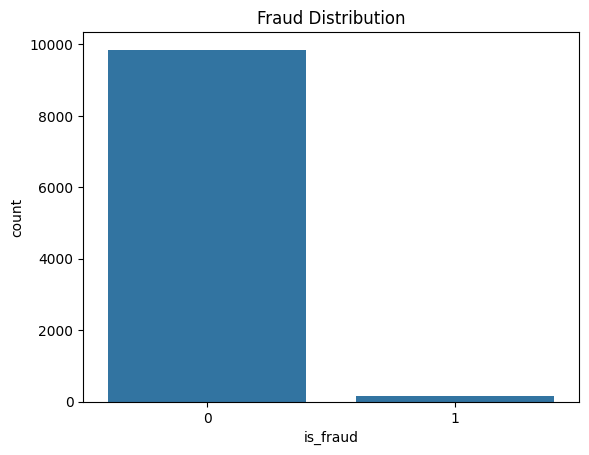

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x="is_fraud",data=df)
plt.title("Fraud Distribution")
plt.show()

This dataset is unbalanced as we can see clearly from this plot

In [9]:
X=df.drop("is_fraud",axis=1)
y=df["is_fraud"]

In [10]:
X=pd.get_dummies(X,columns=['merchant_category'],drop_first=True)

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
Scaler=StandardScaler()
X_train_Scaled=Scaler.fit_transform(X_train)
X_test_scaled=Scaler.transform(X_test)

In [15]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
X_train_smote,y_train_smote=smote.fit_resample(X_train_Scaled,y_train)

In [16]:
print("BEFORE SMOTE : ")
print(y_train.value_counts())

print("\nAfter SMOTE")

print(y_train_smote.value_counts())

BEFORE SMOTE : 
is_fraud
0    7879
1     121
Name: count, dtype: int64

After SMOTE
is_fraud
0    7879
1    7879
Name: count, dtype: int64


In [17]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

svm=SVC(
    kernel='rbf',
    probability=True,
    class_weight='balanced',
    random_state=42
)

In [18]:
svm.fit(X_train_smote,y_train_smote)
svm_pred=svm.predict(X_test_scaled)

In [19]:
print(classification_report(
    y_test,
    svm_pred
))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1970
           1       0.40      0.80      0.53        30

    accuracy                           0.98      2000
   macro avg       0.70      0.89      0.76      2000
weighted avg       0.99      0.98      0.98      2000



In [20]:
from xgboost import XGBClassifier
xgb=XGBClassifier(
    n_estimation=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)
xgb.fit(X_train_smote,y_train_smote)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:30:13] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimation" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimation=200, n_estimators=None,
              n_jobs=None, ...)

In [21]:
xgb_pred=xgb.predict(X_test_scaled)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      1970
           1       0.62      1.00      0.77        30

    accuracy                           0.99      2000
   macro avg       0.81      1.00      0.88      2000
weighted avg       0.99      0.99      0.99      2000



In [22]:
from sklearn.metrics import roc_auc_score
xgb_prob=xgb.predict_proba(X_test_scaled)[:,1]
auc = roc_auc_score(
    y_test,
    xgb_prob
)

print("ROC AUC =", auc)

ROC AUC = 0.999610829103215


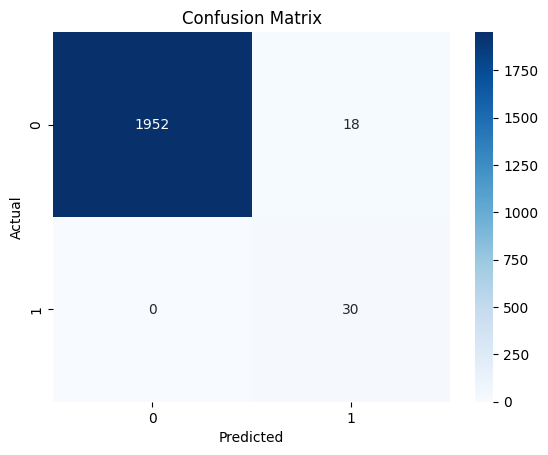

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    xgb_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [24]:
importance = pd.DataFrame({

    "Feature": X.columns,
    "Importance": xgb.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

                          Feature  Importance
2                transaction_hour    0.249304
4               location_mismatch    0.204413
5              device_trust_score    0.165971
3             foreign_transaction    0.161984
6               velocity_last_24h    0.097828
1                          amount    0.031228
11       merchant_category_Travel    0.023783
9          merchant_category_Food    0.015764
0                  transaction_id    0.014246
8   merchant_category_Electronics    0.013502


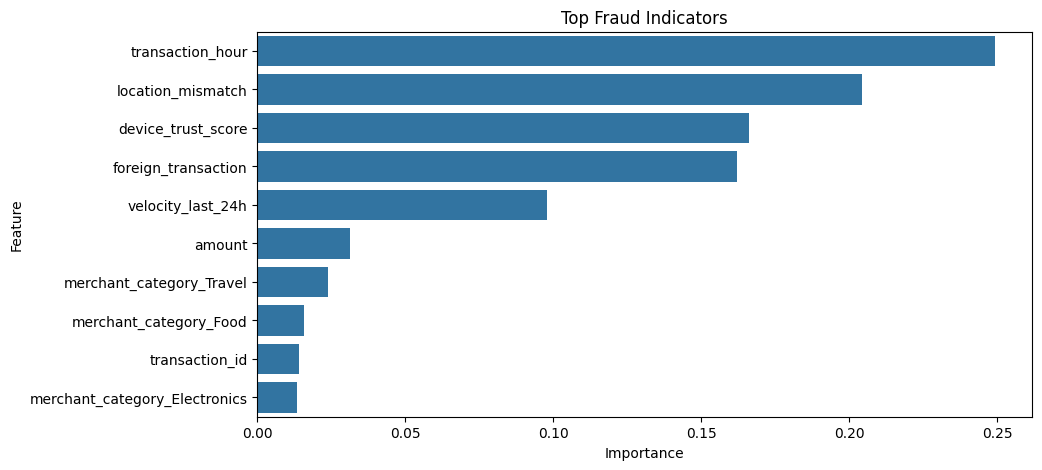

In [25]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top Fraud Indicators")
plt.show()